Obligacija - skolos vertybinis popierius (finansinis instrumentas).

Obligacijos veikimo principas:

*   Emitentas išleidžia obligacijų emisiją su nominalia obligacijos verte F, laikotarpiui, kurio ilgumas yra n
*   Investuotojas perka obligaciją už kainą P (nebūtinai sutampa su nominalia verte)
*   Pinigai nukeliauja pas emitentą, jei pirkimas vykdomas pirminėje rinkoje
*   Emitentas įsipareigoja mokėti kuponus (jeigu obligacija yra kuponinė) visą obligacijos terminą n
*  Obligacijos termino pabaigoje yra išmokamas paskutinis kuponas ir išpirkimo suma C (obligacija išperkama, išpirkimo suma nebūtinai turi sutapti su F)

Tagi žymėjimai yra tokie:
*   F - nominali vertė (kiek vertas šis vertybinis popierius)
*   P - obligacijos kaina
*   C - obligacijos išpirkimo suma
*   r - kupono norma
*   i - obligacijos grąžos norma
*   n - mokėjimų skaičius

Obligacijos grąžos norma i parodo, kokią grąžą gautume, jei idėtume indėlį P į banką, n metų laikotarpiui su palūkanų norma i, su sąlyga, kad visi kuponai gauti iš obligacijos buvo reinvestuoti su i norma.

Kitaip tariant, i tai yra kokią grąžą gauname investuodami į obligaciją (kai visi kuponai buvo reinvestuoti su ta pačia palūkanų norma).

Obligacijos kainos nustatymas:

$$P=Fr\cdot v+Fr\cdot v^2+Fr\cdot v^3 +...+Fr \cdot v^{n-1}+Fr\cdot v^n+C\cdot v^n$$
$$P=\displaystyle\sum_{t=1}^{n}Fr\cdot v^t+C\cdot v^n=Fr\cdot a_{\overline{n}|i}+C\cdot v^n$$

čia $v=\frac{1}{1+i}$ yra diskonto daugiklis, $a_{\overline{n}|i}=\frac{1-(1+i)^{-n}}{i}$ yra anuiteto, kai viena įmoka lygi 1 piniginiam vienetui dabartinė vertė.

**PASTABA**: Šiame darbe obligacijos kainai nustatyti yra naudojama būtent ši formulė, o ji remiasi tokiomis prielaidomis:

1) Atstumas tarp kuponų mokėjimų yra toks pat
2) Kuponas yra mokamas vieną kartą per metus.
3) Mokėjimo periodų skaičius $n$ yra natūralusis skaičius, tačiau kadangi obligacijos kaina turi analizinę išraišką, tai $n$ bus išplėstas iki realiųjų skaičių.

Jeigu tyrinėjami atvejai, kai kuponai mokami dažnumu $m$, tai obligacijos kaina nustatoma remiantis tokia formule:

$$P=\displaystyle\sum_{t=1}^{mn}=\frac{\frac{Fr}{m}}{(1+\frac{i}{m})^t}+\frac{C}{(1+\frac{i}{m})^{mn}}=\frac{Fr}{m} \frac{1-(1+\frac{i}{m})^{-mn}}{\frac{i}{m}}+\frac{C}{(1+\frac{i}{m})^{mn}}$$


Kai ieškoma grąžos norma $i$, tai iš šios formulės bus rasta nominali m-kartų per metus perskaičiuojama norma žymima $i^{(m)}$. Dažniausiai grąža pateikiama, kaip metinė, todėl reikia perskaičiuoti šią normą, kaip efektyvią grąžą (efektyvi palūkanų norma):

$i=(1+\frac{i^{(m)}}{m})^m-1$


Jeigu turima pakankamai išsamių duomenų, tai galima naudoti šią pačią bendriausią obligacijos kainos formulę:

$$P=\displaystyle\sum_{i=1}^{N}\frac{p_i}{(1+r)^{t_i}}$$

(pinigų srauto dabartinė vertė)

$p_i$ - mokėjimai

$r$ - obligacijos gražos norma

$N$ - mokėjimų skaičius

$t_i$ - laikas, metais, nuo šiandien iki $i$ - tojo mokėjimo gavimo datos















In [98]:
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
import sympy as sp
from google.colab import drive
import datetime
import scipy
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [99]:
def obligacijos_kaina(F,C,r,i,n):
  i=i/100
  r=r/100
  v=1/(1+i)
  return F*r*((1-(1+i)**(-n))/i)+C*v**n

obligacija1=obligacijos_kaina(1000,1000,4,6,5)
obligacija2=obligacijos_kaina(1000,1000,5,5,5)
obligacija3=obligacijos_kaina(1000,1000,5,10,10)

obligacijos=[obligacija1,obligacija2,obligacija3]

for el in obligacijos:
  print(el)


915.7527242886854
1000.0
692.7716447147659


Obligacijos grąžos normą galima gauti taikant aproksimacinę formulę:
$$i\approx\frac{g-\frac{k}{n}}{1+\frac{1}{2}k}$$ kur $k=\frac{P-C}{C}$, o $g$ yra modifikuota kupono norma $g=\frac{Fr}{C}$

Tačiau šis metodas nėra visais atvejais tikslus dėl to dažnai naudojamas yra Niutono Rapsono algoritmas:

Mums reikia išspręsti lygtį $f(x)=0$. Niutono Rapsono algoritmas atrodo taip:

$$x_n=x_{n-1}-\frac{f(x_{n-1})}{f'(x_{n-1})}$$

Pagrindiniai reikalavimai šiam algoritmui yra, kad funkcija $y=f(x)$ būtų bent vieną kartą tolydžiai diferencijuojama ir turėtų bent vieną šaknį.

Dabar pritaikysim ši algoritmą obligacijos grąžai nustatyti:

Tam, kad gauti grąžą reikia išspręsti tokią lygtį i atžvilgiu:

$$P=Fr\cdot a_{\overline{n}|i}+C\cdot v^n$$

$$Fr\cdot a_{\overline{n}|i}+C\cdot v^n - P=0$$

$$Fr\frac{1-(1+i)^{-n}}{i}+\frac{C}{(1+i)^n}-P=0$$

Pažymėkim $f(i)=Fr\frac{1-(1+i)^{-n}}{i}+\frac{C}{(1+i)^{n}}-P$

Dabar ieškosim tokio $i$, kad $f(i)=0$

Suskaičiuojam $f'(i)=\frac{df}{di}$:

$$f'(i)=\frac{df}{di}=Fr\frac{ni(1+i)^{-n-1}-1+(1+i)^{-n}}{i^2}-\frac{Cn}{(1+i)^{n+1}}$$

Taikant Niutono Rapsono algoritmą gali iškilti problemų, kai verčiam $i$ dešimtaine trupmena t.y skaičiuojam išvestinę taške $\frac{i}{100}$, nes gaunasi, kad nepriklausomas kintamasis tampa funkcija. Galim žymėti taip: $g(i)=\frac{i}{100}$. Tuomet reikia prisiminti sudėtinės funkcijos išvestinės taisyklę:

$$[f(g(x))]'=f'(g(x))g'(x)x'$$

Taigi mūsų atveju:

$$[f(\frac{i}{100})]'=f'(\frac{i}{100})(\frac{i}{100})'=f'(\frac{i}{100})\cdot \frac{1}{100}$$

Taigi, dabar tiesiog belieka taikyti Niutono Rapsono algoritmą, kad surasti $i$:

$$i_n=i_{n-1}-\frac{f(i_{n-1})}{f'(i_{n-1})}$$


In [100]:
def ddf(F,C,r,i,n):
  r=r/100
  i=i/100
  return F*r*(n*i*(1+i)**(-n-1)-1+(1+i)**(-n))/(i**2)-(C*n)/((1+i)**(n+1))

def f(P,F,C,r,i,n):
  return obligacijos_kaina(F,C,r,i,n)-P

def niutono_rapsono_graza(P,F,C,r,n,x0=5):
  s=x0
  epsilon=10**(-5)
  iteracijos=0
  while (abs(f(P,F,C,r,s,n))>epsilon):
    if iteracijos>10000:
      return "Klaida"
    xn=s-(f(P,F,C,r,s,n)/(ddf(F,C,r,s,n)/100))
    s=xn
    iteracijos+=1
  return s

niutono_rapsono=np.vectorize(niutono_rapsono_graza)
niutono_rapsono_graza(1000,1000,1000,5,5,6)

4.999999999987093

In [101]:
def obligacijos_grazos_norma(P,F,C,r,n):
  r=r/100
  k=(P-C)/C
  g=(F*r)/C
  return (g-k/n)/(1+k/2)

graza1=obligacijos_grazos_norma(1000,1000,1000,5,5)
graza2=obligacijos_grazos_norma(800,1000,1200,3,10)
graza3=obligacijos_grazos_norma(600,1000,1000,7,6)

grazos=[graza1,graza2,graza3]

for el in grazos:
  el=round(el*100,2)
  print(el)


5.0
7.0
17.08


Obligacijos kainos nustatymo formulėje visi parametrai $F,C,r,n$, išskyrus $P$ ir $i$, yra fiksuoti. Keistis gali tik obligacijos kaina $P$ ir jos grąžos norma $i$. Vadinasi obligacijos kaina yra grąžos normos funkcija:

$$P(i)=Fr\cdot a_{\overline{n}|i}+C\cdot v^n$$

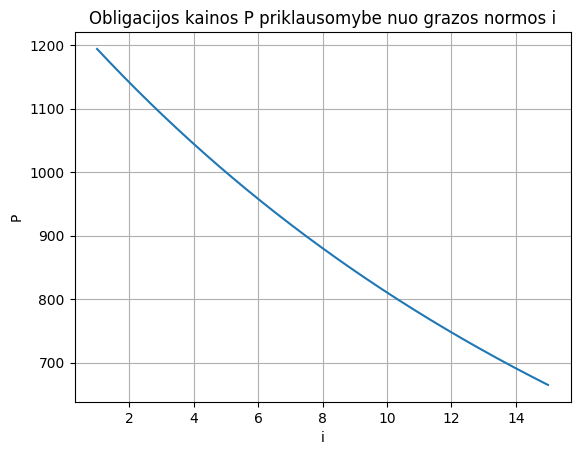

In [102]:
obligacijos_grazos_norma=np.vectorize(obligacijos_grazos_norma)
i_reiksmes=np.linspace(1,15,10000)

F=1000
C=1000
r=5
i=i_reiksmes
n=5
kainos=obligacijos_kaina(F,C,r,i,n)

plt.plot(i_reiksmes,kainos)
plt.xlabel("i")
plt.ylabel("P")
plt.title("Obligacijos kainos P priklausomybe nuo grazos normos i")
plt.grid()


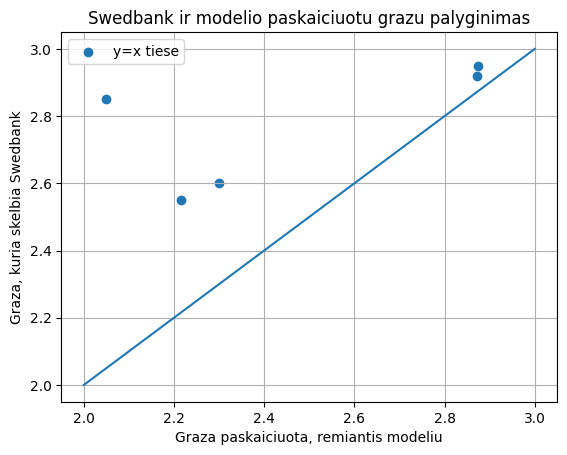

In [103]:
swed_bond=pd.read_csv('/content/drive/MyDrive/swed_bond_data.csv',sep=";")
swed_bond['Years']=swed_bond['Time (Days)']/365
swed_bond['Calculated YTM']=niutono_rapsono(swed_bond['Price'],swed_bond['Nominal'],swed_bond['Nominal'],swed_bond['Coupon (%)'],swed_bond['Years'])
swed_bond['Error']=abs(swed_bond['Calculated YTM']-swed_bond['Yield (%)'])
swed_bond.head()

swed_ytm=swed_bond['Yield (%)'].values
model_ytm=swed_bond['Calculated YTM'].values
plt.figure()
x=np.linspace(2,3,30)
y=x
plt.plot(x,y)
plt.scatter(model_ytm,swed_ytm,label="y=x tiese")
plt.xlabel("Graza paskaiciuota, remiantis modeliu")
plt.ylabel("Graza, kuria skelbia Swedbank")
plt.title("Swedbank ir modelio paskaiciuotu grazu palyginimas")
plt.grid(True)
plt.legend()
plt.show()


Obligacijų rinkoje obligacijos kaina yra vadinama švaria kaina (clean price), bet obligacijos pirkėjas sumoka nešvarią kainą (dirty price) t.y kainą su susikaupusiomis palūkanomis nuo paskutinio kupono (accrued interest)

Nešvari kaina $=$ Švari kaina $+$ Susikaupusios palūkanos

Toks mechanizmas yra, kai obligacija perkama tarp kuponų mokėjimų.

In [104]:
# 2026-04-22 NASDAQ biržos duomenys apie obligacijas
df=pd.read_csv('/content/drive/MyDrive/bonds_data4.csv',sep=";")
df=df.set_index('Pavadinimas')
obligacijos=df.copy()

stulpeliai=['Bond segment','Nominali','Atkarpa (%)','Išpirkimo data','Švari kaina','Sukauptos palūkanos']
obligacijos=obligacijos.loc[:,stulpeliai]
obligacijos=obligacijos.dropna()
obligacijos['Švari kaina']=obligacijos['Švari kaina'].str.replace(',','.').astype(float)
obligacijos['Sukauptos palūkanos']=obligacijos['Sukauptos palūkanos'].str.replace(',','.').astype(float)
obligacijos['Atkarpa (%)']=obligacijos['Atkarpa (%)'].str.replace(',','.').astype(float)
obligacijos['Nominali']=obligacijos['Nominali'].astype(float)
obligacijos['Kaina']=obligacijos['Nominali']*((obligacijos['Švari kaina']+obligacijos['Sukauptos palūkanos'])/100)
#obligacijos=obligacijos.loc[:,['Nominali','Atkarpa (%)','Išpirkimo data','Kaina','Bond segment']]
obligacijos['Išpirkimo data']=pd.to_datetime(obligacijos['Išpirkimo data'])
delta=(obligacijos['Išpirkimo data']-pd.Timestamp(2026,8,19)).dt.days
delta=delta/365
obligacijos['Laikotarpis']=delta
#obligacijos['Graza']=niutono_rapsono(obligacijos['Kaina'],obligacijos['Nominali'],obligacijos['Nominali'],obligacijos['Atkarpa (%)'],obligacijos['Laikotarpis'])
obligacijos=obligacijos[obligacijos['Laikotarpis']>0]
obligacijos['Graza']=niutono_rapsono((obligacijos['Švari kaina']/100)*obligacijos['Nominali'],obligacijos['Nominali'],obligacijos['Nominali'],obligacijos['Atkarpa (%)'],obligacijos['Laikotarpis'])
obligacijos=obligacijos[(obligacijos['Graza']>0) & (obligacijos.index!='Amber Beverage Group Holding 4Y')]

obligacijos.head(50)



,Bond segment,Nominali,Atkarpa (%),Išpirkimo data,Švari kaina,Sukauptos palūkanos,Kaina,Laikotarpis,Graza
Pavadinimas,,,,,,,,,
Panevezio stiklas 8.50% 3Y bond,First North obligacijų sąrašas,1000.0,8.500,2029-04-24,102.000,0.613889,1026.138890,2.682192,7.647191
Admiral Markets 8% subord. bond,Bendrovių obligacijos,100.0,8.000,2027-12-28,103.000,1.155556,104.155556,1.358904,5.644873
Atsin.energ.investicijos 8.5% 1Y,Bendrovių obligacijos,1000.0,8.500,2026-12-04,100.000,2.494565,1024.945650,0.293151,8.500000
Apollo Group 7% 5Y bond,Bendrovių obligacijos,500.0,7.000,2031-03-20,97.600,0.388889,489.944445,4.586301,7.639870
Arco Vara 8.8% 3Y bond,Bendrovių obligacijos,100.0,8.800,2028-09-24,100.900,1.368889,102.268889,2.101370,8.315670
Bigbank 6.5% subord. bond,Bendrovių obligacijos,1000.0,6.500,2034-10-23,102.000,1.173611,1031.736110,8.183562,6.181281
Bigbank 6.5% subord. Bond,Bendrovių obligacijos,1000.0,6.500,2035-06-27,102.690,1.173611,1038.636110,8.860274,6.098076
Bigbank 7.00% subord. bond,Bendrovių obligacijos,1000.0,7.000,2034-05-29,103.500,1.263889,1047.638890,7.780822,6.414627
Bigbank 8.00% subord.bond,Bendrovių obligacijos,1000.0,8.000,2032-09-21,103.500,1.311111,1048.111110,6.095890,7.268971


Labai svarbu yra įvertinti obligacijos palūkanų normos riziką t.y kiek pasikeis obligacijos kaina, jeigu palūkanų norma i pasikeis nedaug (obligacijos jautrumas palūkanų normai). Tam naudojamas kintamumas (modifikuota trukmė):

$$\bar v=-\frac{P'(i)}{P(i)}$$

Šis rizikos parametras parodo, kaip pasikeis obligacijos kaina (procentais), jeigu palūkanų norma pasikeis 1 %.

Pvz: Gauta, kad $\bar v=4$, tai reiškia:

Palūkanų normai padidėjus 1% obligacijos kaina krenta 4%

Palūkanų normai sumažėjus 1% obligacijos kaina kyla 4%


Kodėl tai rodo procentinį pokytį?

Jeigu aproksimuosim išvestinę $P'(i)$, kaip $\frac{\Delta P}{\Delta i}$, tai gausim:

$$\bar v=-\frac{\frac{\Delta P}{\Delta i}}{P}$$

$\;$

$$\bar v=-\frac{\Delta P}{P \Delta i}$$

$\;$
$$-\bar v \Delta i=\frac{\Delta P}{P}$$

Jeigu tariam, kad $\Delta i=0,01$ t.y palūkanos kinta 1%, tai

$$-\bar v=\frac{\Delta P}{P}\cdot 100$$

Matome, kad dešinėje pusėje yra procentinis pokytis.

Turint kintamumą galima įvertinti naują obligacijos kainą:

Iš Teiloro formulės:

$$P(i+h)\approx P(i)+P'(i)h$$

Kadangi $P'(i)=- \bar v P(i)$, tai:

$$P(i+h)\approx P(i)-\bar v P(i)h=P(i)(1-\bar v h)$$

Šia formule ir galima aproksimuoti naują kainą, kai palūkanų norma keičiasi 1%.

Kitas rizikos parametras yra iškilumas, kuris parodo, kiek išgaubta yra funkcija $P(i)$ ir jis apibrėžiamas taip:

$$\bar c=\frac{P''(i)}{P(i)}$$

Kuo didesnis iškilumo koeficientas $\bar c$ tuo investuotojui yra geriau, nes:

Palūkanų normai kylant, kainos krenta mažiau

Palūkanų normai krentant kainos auga daugiau

Dabar galima patobulinti obligacijos kainos įvertinimą, kai palūkanų norma pasikeičia nedaug:

Naudosime Teiloro formulę $$P(i+h)=P(i)+P'(i)h+\frac{P''(i)}{2!}h^2+o(h^2)$$

$$P(i+h)\approx P(i)+P'(i)h+\frac{P''(i)}{2!}h^2$$

$\;$

$$P(i+h)\approx P(i)-P(i)\bar vh+\frac{P''(i)}{2P(i)}P(i)h^2$$

$$P(i+h)\approx P(i)-P(i)\bar vh+\frac{1}{2}P(i)h^2\bar c$$

$$P(i+h)\approx P(i)(1-\bar vh+\frac{h^2}{2}\bar c)$$

Ši paskutinė formulė leidžia tiksliau aproksimuoti, kokia yra nauja kaina, kai palūkanos pakinta nedaug

In [105]:
i,F,r,n,C=sp.symbols('i F r n C')
kainos_isvest_f=F*r*((n*i*(1+i)**(-n-1)-1+(1+i)**(-n))/i**2)-((C*n)/((1+i)**(n+1)))
kainos_isvest2_f=sp.diff(kainos_isvest_f,i)

def kintamumas(F,C,r,i,n):
  kaina=obligacijos_kaina(F,C,r,i,n)
  kainos_isvestine=ddf(F,C,r,i,n)
  return -kainos_isvestine/kaina

def iskilumas(nom,isp,kup,pal,laik):
  reiksmes={i:pal/100,F:nom,r:kup/100,n:laik,C:isp}
  kaina=obligacijos_kaina(nom,isp,kup,pal,laik)
  kainos_isvestine2=kainos_isvest2_f.subs(reiksmes)
  return kainos_isvestine2/kaina

def pasikeitus_kaina(F,C,r,i,n,h):
  kaina=obligacijos_kaina(F,C,r,i,n)
  v=kintamumas(F,C,r,i,n)
  c=iskilumas(F,C,r,i,n)
  h=h/100
  return kaina*(1-v*h+(h**2/2)*c)

h=2
kintamumas=np.vectorize(kintamumas)
pasikeitus_kaina=np.vectorize(pasikeitus_kaina)
obligacijos['Kintamumas']=kintamumas(obligacijos['Nominali'],obligacijos['Nominali'],obligacijos['Atkarpa (%)'],obligacijos['Graza'],obligacijos['Laikotarpis'])
obligacijos['Palukanu pokytis %']=h
obligacijos['Pasikeitusi kaina']=pasikeitus_kaina(obligacijos['Nominali'],obligacijos['Nominali'],obligacijos['Atkarpa (%)'],obligacijos['Graza'],obligacijos['Laikotarpis'],h)
obligacijos['Reali kaina po pokycio']=obligacijos_kaina(obligacijos['Nominali'],obligacijos['Nominali'],obligacijos['Atkarpa (%)'],obligacijos['Graza']+h,obligacijos['Laikotarpis'])
obligacijos['Paklaida']=abs(obligacijos['Reali kaina po pokycio']-obligacijos['Pasikeitusi kaina'])
obligacijos.head()




,Bond segment,Nominali,Atkarpa (%),Išpirkimo data,Švari kaina,Sukauptos palūkanos,Kaina,Laikotarpis,Graza,Kintamumas,Palukanu pokytis %,Pasikeitusi kaina,Reali kaina po pokycio,Paklaida
Pavadinimas,,,,,,,,,,,,,,
Panevezio stiklas 8.50% 3Y bond,First North obligacijų sąrašas,1000.0,8.5,2029-04-24,102.0,0.613889,1026.138890,2.682192,7.647191,2.332050,2,974.016682878610,973.972260,0.0444228668485493
Admiral Markets 8% subord. bond,Bendrovių obligacijos,100.0,8.0,2027-12-28,103.0,1.155556,104.155556,1.358904,5.644873,1.269126,2,100.443712232286,100.442508,0.00120410483233968
Atsin.energ.investicijos 8.5% 1Y,Bendrovių obligacijos,1000.0,8.5,2026-12-04,100.0,2.494565,1024.945650,0.293151,8.500000,0.278018,2,994.506548563797,994.505615,0.000933086414875106
Apollo Group 7% 5Y bond,Bendrovių obligacijos,500.0,7.0,2031-03-20,97.6,0.388889,489.944445,4.586301,7.639870,3.781989,2,452.925134066385,452.854227,0.0709073747840989
Arco Vara 8.8% 3Y bond,Bendrovių obligacijos,100.0,8.8,2028-09-24,100.9,1.368889,102.268889,2.101370,8.315670,1.854246,2,97.2636202369772,97.261039,0.00258153196591593


Baltijos obligacijų sąrąšą sudaro daugybė įmonių obligacijų, taip pat ir valstybių obligacijos ir žemiau pateiktame grafike galima matyti, kad nors likęs laikas iki obligacijų išpirkimo yra panašus, grąža labai skiriasi. Taip yra dėl kredito premijos. Kadangi skiriasi daugumos emitentų kredito rizika, tai nors laikas likęs iki išpirkimo yra panašus, grąža gali žymiai skirtis.

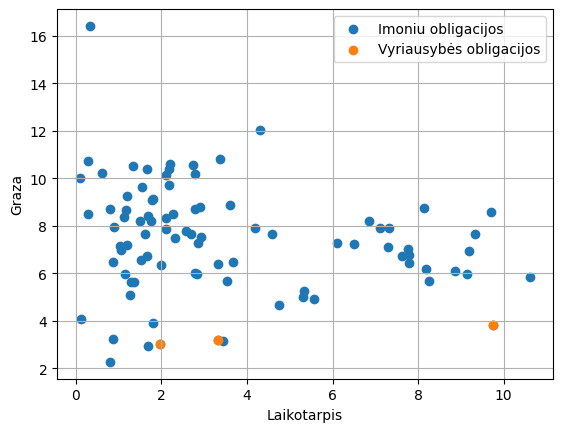

In [106]:
stulp=['Nominali','Atkarpa (%)','Kaina','Laikotarpis','Graza','Kintamumas','Bond segment']
ob=obligacijos.loc[:,stulp]

ob=ob.sort_values('Laikotarpis')
plt.scatter(ob['Laikotarpis'].values,ob['Graza'].values,label='Imoniu obligacijos')
vyrob=ob[ob['Bond segment']=='Vyriausybės obligacijos']
plt.scatter(vyrob['Laikotarpis'],vyrob['Graza'],label='Vyriausybės obligacijos')
plt.xlabel("Laikotarpis")
plt.ylabel("Graza")
plt.legend()
plt.grid()
plt.show()


Šiame grafike galima pastebėti, kad baltijos šalių obligacijų duomenyse yra tendencija, rodanti, kad didesnė atkarpa reiškia didesnę grąžą.

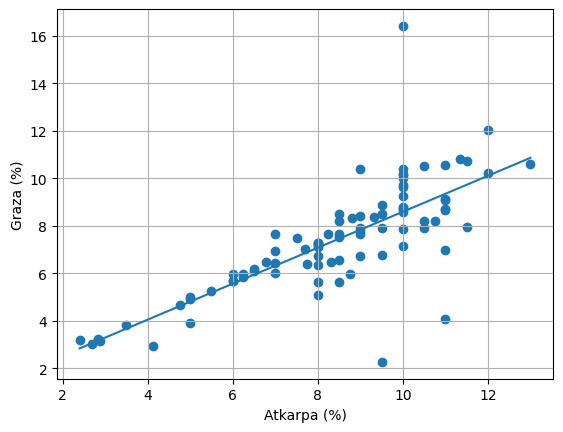

0.7582981385063217
1.1749804781679887e-17


In [107]:
ob1=ob.sort_values('Atkarpa (%)')
kuponas=ob1['Atkarpa (%)']
graza=ob1['Graza']
plt.scatter(kuponas,graza)
plt.xlabel("Atkarpa (%)")
plt.ylabel("Graza (%)")
plt.grid()

from scipy import stats

slope, intercept, r, p, std_err = stats.linregress(kuponas, graza)

def reg(x):
  return slope*x+intercept

model=list(map(reg,kuponas))
plt.plot(kuponas,model)
plt.show()

print(r)
print(p)


Iš šios analizės matoma, kad egzistuoja stiprus tiesinis ryšys tarp kintamumo ir laikotarpio. Vadinasi kuo ilgesnes trukmės obligacija tuo didesnis jos kintamumas.

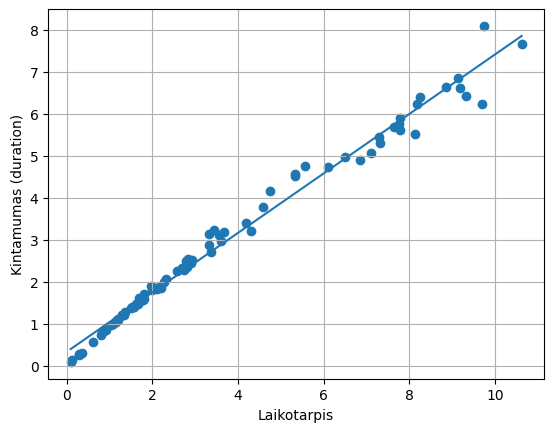

0.9929120479240965


In [108]:
ob2=ob.sort_values('Laikotarpis')
laikotarpis=ob2['Laikotarpis']
duration=ob2['Kintamumas']
plt.scatter(laikotarpis,duration)
plt.xlabel("Laikotarpis")
plt.ylabel("Kintamumas (duration)")
plt.grid()


slope, intercept, r, p, std_err = stats.linregress(laikotarpis, duration)

def reg1(x):
  return slope*x+intercept

model1=list(map(reg1,laikotarpis))

plt.plot(laikotarpis,model1)

plt.show()

print(r)

Toliau darbas bus susijęs su pajamingumo kreivės konstravimu. Naudojami duomenys: Vokietijos Federacinės respublikos obligacijos, kurių:
1) Laikotarpis iki išpirkimo yra iki 10 metų.
2) Palūkanos priskaičiuojamas vieną kartą per metus
3) Nominalas nurodomas procentais, nes galima pirkti kokio tik norima nominalo, bet bus imamas 100 Eur
4) Kainos yra nurodytos 10 dienų laikotarpiui
5) Naudojamos uždarymo (close) kainos
6) Nurodytos išpirkimo datos
7) Nurodytas kupono dydis procentais
8) Nurodytas kiekvienos obligacijos ISIN (International Securities Identification Number) - uniklaus obligacijos identifikatorius

Naudojamų duomenų laikotarpis:

2026-11-13 iki 2026-11-23

Duomenys imami iš Frankfurto vertybinių popierių biržą valdančios įmonės Deutsche Börse internetinio puslapio:

https://live.deutsche-boerse.com/bonds


Kainų duomenys yra pateikiami, kaip švari kaina (clean price), bet pajamingumo kreivė konstruojama naudojant nešvarią kainą (dirty price)

$$Dirty Price = Clean Price +Accrued Interest$$

Vadinasi nešvari kaina susideda iš švarios kainos ir susikaupusių palūkanų, kurios skaičiuojamos taip:

$$AI=\frac{\text{dienu sk nuo paskutinio kupono datos iki pirkimo datos}}{365}\cdot Fr$$

**PASTABA**:
Vietoje vardiklyje esančio skaičiaus 365 gali būti naudojamas ir kitas skaičius pagal susitartą konveciją, kurios yra:
1) 30/360 taisyklė
2) Tikslus/360
3) Tikslus/Tikslus

Bus konstruojama YTM (yield to maturity) kreivė ir spot rate (taškinių palūkanų normų) kreivė


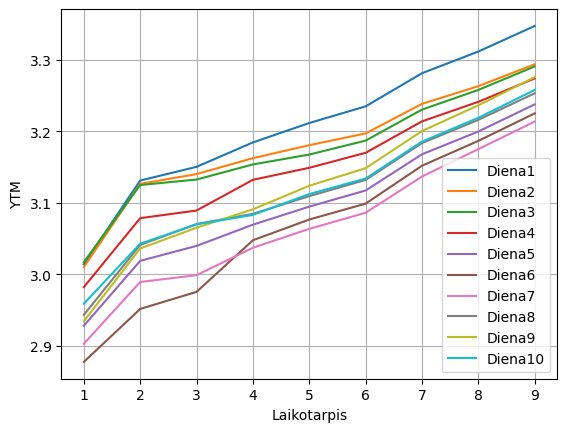

In [109]:
# Nuskaitom duomenis
from dateutil.relativedelta import relativedelta
df=pd.read_csv('/content/drive/MyDrive/data_yield_curve_papildytas.csv',sep=";")

df=df.set_index('ISIN')
df.head()

df1=pd.DataFrame()
df2=pd.DataFrame()
df3=pd.DataFrame()
df4=pd.DataFrame()
df5=pd.DataFrame()
df6=pd.DataFrame()
df7=pd.DataFrame()
df8=pd.DataFrame()
df9=pd.DataFrame()
df10=pd.DataFrame()

sar=[df1,df2,df3,df4,df5,df6,df7,df8,df9,df10]


def paskutinis_kuponas(ispirk_date,pirk_date):
  '''
  Is ispirkimo datos, kuri taip pat yra kupono mokejimo data perkelia i dabartine pirkimo diena
  Tuomet matome, kada tais metais buvo mokamas kuponas
  Pirmas atvejis, kad kuponas dar nesumoketas --> kupono data yra veliau uz pirkimo data, tuomet reikia atimti metus
  Antras atvejis, kad kuponas buvo sumoketas --> atimti metu nereikia, tai ir bus kupono mokejimo data
  '''
  metai=ispirk_date.year-pirk_date.year
  t=ispirk_date-relativedelta(years=metai)
  if t>pirk_date:
    t=t-relativedelta(years=1)
  return t


for i in range(10):
  sar[i]=df.iloc[:,[i,i+10,20,21,22,23]]
  datfr=sar[i].copy()
  datfr['Ispirkimas']=pd.to_datetime(datfr['Ispirkimas'])
  datfr[datfr.columns[0]]=pd.to_datetime(datfr.iloc[:,0])
  datfr['Laikotarpis']=((datfr['Ispirkimas']-datfr.iloc[:,0]).dt.days)/365
  datfr['Pask_kup_mok']=[paskutinis_kuponas(a,b) for a,b in zip(datfr['Ispirkimas'],datfr[datfr.columns[0]])]
  datfr['Dienu_sk']=(datfr[datfr.columns[0]]-datfr['Pask_kup_mok']).dt.days
  datfr['AI']=(datfr['Dienu_sk']/365)*datfr['Nominalas']*(datfr['Kuponas (%)']/100)
  datfr['Dirty_Price']=datfr[datfr.columns[1]]+datfr['AI']
  datfr['Graza (%)']=niutono_rapsono(datfr[datfr.columns[1]],datfr['Nominalas'],datfr['Nominalas'],datfr['Kuponas (%)'],datfr['Laikotarpis'])
  sar[i]=datfr

# I niutono rapsono funkcija statome clean kaina, del to gaunasi grazi ytm kreive

for i in range(10):
  dat=sar[i]
  laikotarpiai=dat['Laikotarpis']
  grazos=dat['Graza (%)']
  t = list(i for i in range(1, 10))
  t_naujas=[]
  y_reiksmes = []
  j=0
  interp = scipy.interpolate.interp1d(laikotarpiai, grazos, bounds_error=False, fill_value=np.nan)
  for i in t:
    value = float(interp(i))
    if not np.isnan(value):
        y_reiksmes.append(value)
        t_naujas.append(i)
        j+=1
  plt.plot(t_naujas,y_reiksmes,label=dat.columns[0])
plt.grid(True)
plt.xlabel('Laikotarpis')
plt.ylabel('YTM')
plt.legend()
plt.show()



Tam, kad surasti spot rates bus taikomas Bootstraping metodas, kurio esmė yra rekursinės procedūros pagalba surasti taškines palūkanų normas
$$s_1,s_2,s_3,...,s_n$$

Obligaicijos kaina, naudojant spot rates yra:
$$P=\sum_{k=1}^n \frac{Fr}{(1+s_k)^{t_k}}+\frac{C}{(1+s_n)^{t_n}}=P=\sum_{k=1}^{n-1} \frac{Fr}{(1+s_k)^{t_k}}+\frac{Fr+C}{(1+s_n)^{t_n}}$$

Jei pažymėsime $B :=\sum_{k=1}^{n-1} \frac{Fr}{(1+s_k)^{t_k}}$ ir išspręsime lygtį $s_n$ atžvilgiu, tai gausime:
$$s_n=\left(\frac{Fr+C}{P-B} \right)^{\frac{1}{t_n}}-1$$

Ir taip rekursiškai gaunamos taškinės palūkanų normos (spot rates)

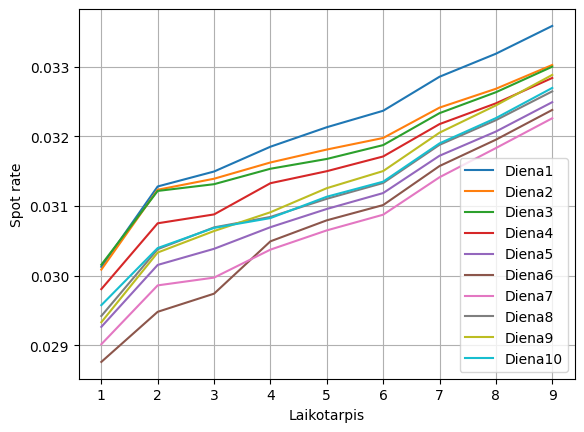

In [110]:
for i in range(len(sar)):
  dat=sar[i].sort_values(by='Laikotarpis')
  n=len(dat)
  laikotarpiai=[]
  spot_rates=[]
  for j in range(n):
    kuponas=dat.iloc[j,3]*dat.iloc[j,2]/100
    laikotarpis=dat.iloc[j,6]
    k=dat.iloc[j,4].year-dat.iloc[j,7].year
    B=0
    for m in range(1,k):
      B+=kuponas/(1+np.interp(laikotarpis-m,laikotarpiai,spot_rates))**(laikotarpis-m)
    s=((dat.iloc[j,3]+kuponas)/(dat.iloc[j,10]-B))**(1/laikotarpis)-1
    laikotarpiai.append(laikotarpis)
    spot_rates.append(s)
  t = list(i for i in range(1, 10))
  t_naujas=[]
  y_reiksmes = []
  h=0
  interp = scipy.interpolate.interp1d(laikotarpiai, spot_rates, bounds_error=False, fill_value=np.nan)
  for el in t:
    value = float(interp(el))
    if not np.isnan(value):
        y_reiksmes.append(value)
        t_naujas.append(el)
        h+=1
  plt.plot(t_naujas,y_reiksmes,label=dat.columns[0])
plt.grid(True)
plt.xlabel('Laikotarpis')
plt.ylabel('Spot rate')
plt.legend()
plt.show()

